# Ship ADCP quick-look (VmDas)

Quick-look of VmDas ship ADCP data (`.LTA` / `.STA`) during a cruise.

Reads the RDI PD0 binary files written by VmDas, converts the ship-relative velocities to absolute (Earth-referenced) currents, applies basic QC and produces:

- time-depth sections of u, v and speed
- a map of the ship track with currents averaged over a depth layer and along track
- a NetCDF file with the processed data

**Notes**

- Use only closed files: copy them from the acquisition PC instead of reading files VmDas is still writing. Incomplete ensembles at the end of a file are skipped anyway.
- Velocities in `.LTA` / `.STA` are **relative to the ship**. Absolute currents are obtained by adding the ship velocity from GPS (`REF = "nav"`) or from bottom track (`REF = "bt"`). Bottom track is lost off the shelf, so GPS is the default.
- VmDas does not flag bins below the bottom unless `PRMarkBadBelowBottom=TRUE` in the `.VMO`. Here they are masked using the bottom-track depth.
- This is a quick-look tool for use at sea. It does **not** replace proper post-processing (e.g. CODAS / pycurrents), which calibrates transducer misalignment and scale factor.

The reader and processing functions are in `../src/vmdas.py` (PD0 reader) and `../src/adcp_quicklook.py` (absolute velocities, QC and plots).

Requirements: `numpy`, `xarray`, `matplotlib`, `cmocean`, `netCDF4`

In [8]:
import os
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "../src")
from adcp_quicklook import output_stem, plot_map, plot_sections, process
from vmdas import list_deployments, load

%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configuration

In [9]:
DATA_DIR = "../data/ADCP_data"     # folder with the VmDas files (closed files only)
DEPLOYMENT = "SOCIB_CabreraSummer26004"  # name as in the file names (DeploymentName + 3-digit number);
                                         # output files are named after it
EXT = "STA"                # "LTA", "STA" or "ENX"
REF = "nav"                # reference for absolute velocities: "nav" (GPS) or "bt" (bottom track)

LAYER = (20, 60)           # depth layer (m) for the map vectors
MAP_DX_KM = 1              # along-track averaging distance (km) for the map vectors; None = every ensemble
VMAX = 0.2                 # colour limit for the sections (m/s)
MAX_DEPTH = None           # max depth in the sections (m); None = automatic
TRANSDUCER_DEPTH = None    # transducer depth (m); None = read from the .VMO

# QC
PG_MIN = 50                # minimum percent good (4-beam solutions)
ERR_MAX = 0.2              # maximum absolute error velocity (m/s)
SIDELOBE_CELLS = 1         # side-lobe cut: mask bins deeper than cos(beam angle) * bottom range - SIDELOBE_CELLS cells; None disables
DV_MAX = 1.0               # mask ensembles where the ship velocity jumps more than this (m/s); None disables

# Output
FIG_DIR = "../figures/adcp_quicklook"  # output figures
NC_DIR = "../data/ADCP_quicklook"      # output NetCDF (not versioned)
SAVE_FIGS = False
SAVE_NC = False

## Load data

Deployments available in `DATA_DIR`:

In [10]:
for dep, files in list_deployments(DATA_DIR, EXT).items():
    print("%-35s %d %s files" % (dep, len(files), EXT))

SOCIB_CabreraSummer26004            1 STA files
SOCIB_CabreraSummer26005            1 STA files


In [11]:
ds = load(DATA_DIR, DEPLOYMENT, EXT, TRANSDUCER_DEPTH)
print("Deployment:", ds.attrs["deployment"])
print("%d ensembles, %s -> %s" % (ds.sizes["time"], str(ds.time.values[0])[:19],
                                 str(ds.time.values[-1])[:19]))
print("Files:", ds.attrs["source_files"])
print()
print("VmDas settings (.VMO):")
for k, v in ds.attrs.items():
    if k.startswith("vmdas_"):
        print("  %-24s %s" % (k[6:], v))

Deployment: SOCIB_CabreraSummer26004
89 ensembles, 2026-07-13T07:29:10 -> 2026-07-13T10:25:09
Files: SOCIB_CabreraSummer26004_000000.STA

VmDas settings (.VMO):
  mark_bad_below_bottom    FALSE
  manual_beam_angle        30
  alignment_EA             44.1
  scale_factor             1.0065
  sta_seconds              120
  lta_seconds              600
  transducer_depth         2


### Check: ship velocity from GPS vs bottom track

Where bottom track is available, the ship velocity from GPS should match minus the bottom-track velocity. A large mean difference points to a navigation, heading or calibration problem.

Ensembles with BT: 72 / 89
GPS - BT  u: mean -0.016, std 0.069 m/s
GPS - BT  v: mean 0.012, std 0.076 m/s


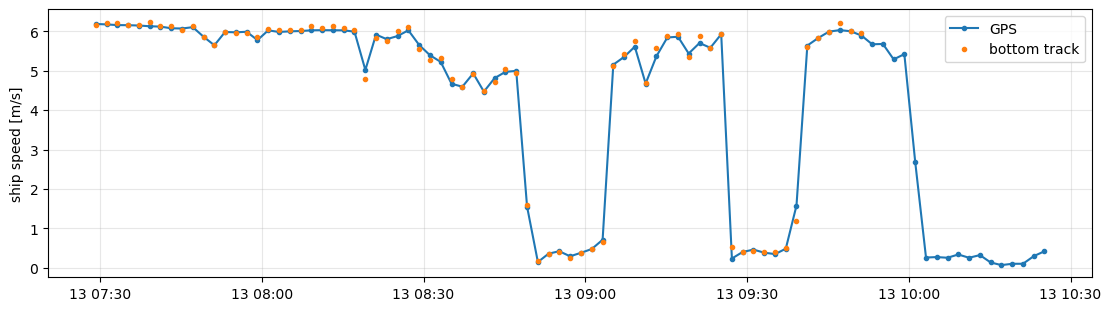

In [12]:
du = ds.ship_u + ds.bt_u
dv = ds.ship_v + ds.bt_v
n = int(np.isfinite(du).sum())
print("Ensembles with BT: %d / %d" % (n, ds.sizes["time"]))
if n:
    print("GPS - BT  u: mean %.3f, std %.3f m/s" % (float(du.mean()), float(du.std())))
    print("GPS - BT  v: mean %.3f, std %.3f m/s" % (float(dv.mean()), float(dv.std())))

fig, ax = plt.subplots(figsize=(11, 3), constrained_layout=True)
ax.plot(ds.time, np.hypot(ds.ship_u, ds.ship_v), ".-", label="GPS")
ax.plot(ds.time, np.hypot(ds.bt_u, ds.bt_v), ".", label="bottom track")
ax.set_ylabel("ship speed [m/s]")
ax.legend()
ax.grid(alpha=0.3)

## Absolute velocities and QC

In [13]:
ds = process(ds, ref=REF, pg_min=PG_MIN, err_max=ERR_MAX, sidelobe_cells=SIDELOBE_CELLS, dv_max=DV_MAX)

masked = ds.time.values[ds.ship_changing.values == 1]
print("Ensembles masked (ship starting/stopping/turning):",
      [str(t)[:16].replace("T", " ") for t in masked])
print("Valid data: %.0f %% of bins" % (100 * float(ds.u.notnull().mean())))

Ensembles masked (ship starting/stopping/turning): ['2026-07-13 08:49', '2026-07-13 09:03', '2026-07-13 09:39', '2026-07-13 10:01']
Valid data: 21 % of bins


## Sections

Output name: SOCIB_CabreraSummer26004_000000_STA


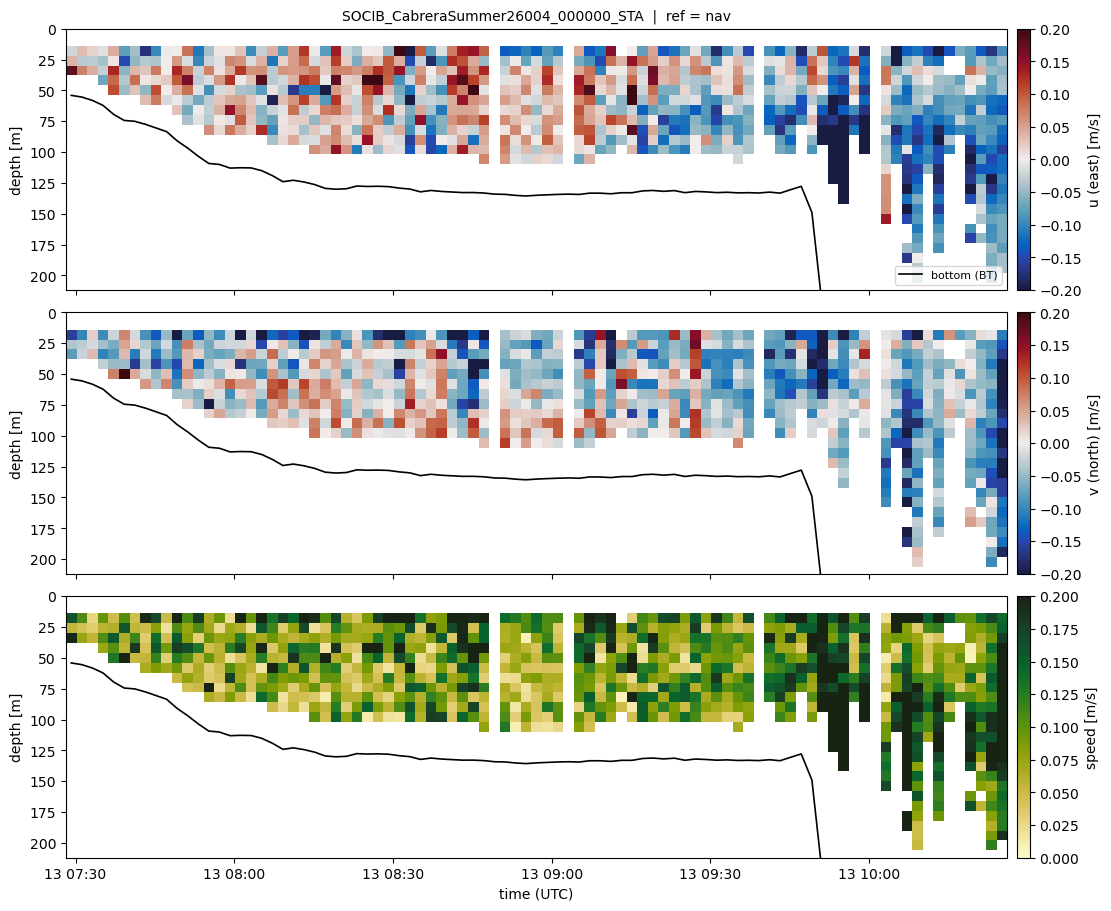

In [14]:
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(NC_DIR, exist_ok=True)
stem = os.path.join(FIG_DIR, output_stem(ds))
nc_file = os.path.join(NC_DIR, output_stem(ds) + ".nc")
print("Output name:", output_stem(ds))

fig = plot_sections(ds, stem + "_sections.png" if SAVE_FIGS else None,
                    vmax=VMAX, max_depth=MAX_DEPTH)

## Map

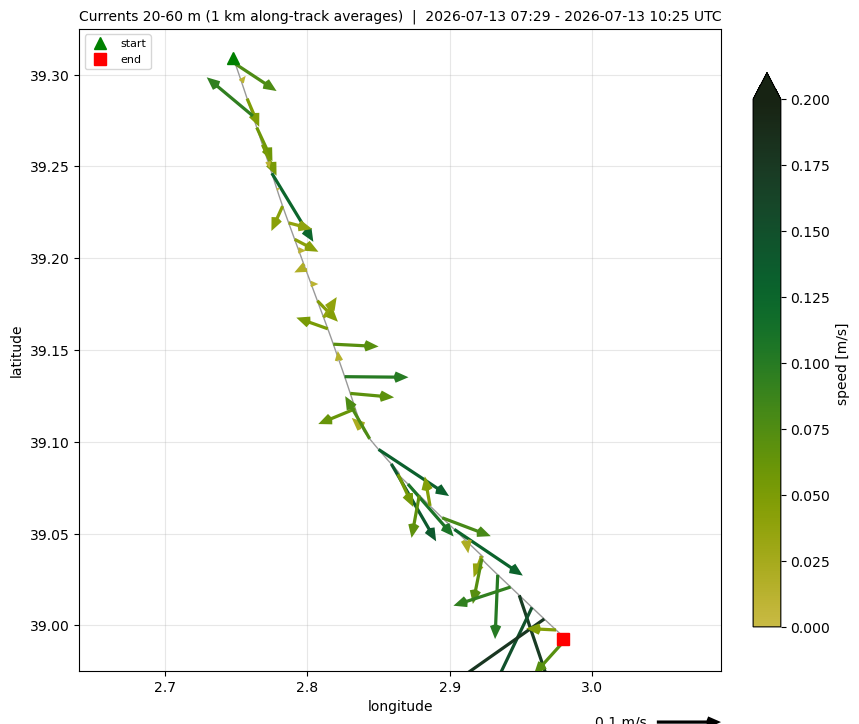

In [15]:
fig = plot_map(ds, stem + "_map.png" if SAVE_FIGS else None, layer=LAYER, dx_km=MAP_DX_KM)

## Save NetCDF

In [16]:
if SAVE_NC:
    ds.to_netcdf(nc_file)
    print("Saved", os.path.abspath(nc_file))